In [288]:
!pip3 install numpy matplotlib pandas tqdm

In [16]:
import numpy as np
import math
import matplotlib.pyplot as plt
import importlib
import util
importlib.reload(util)

<module 'util' from '/home/ilya/Desktop/teorver_laba/5/util.py'>

In [2]:
np.random.seed(66)

## 1. Реализовать алгоритм генерации случайной величины через $F^{-1}$

In [76]:
# Реализуем вычисление функции F из условия

def const(c):
    return lambda x: c

def exp_func(c):
    return lambda x: c - 0.6 * math.exp(-2 * x)

bounds = [
    (-4, const(0)),
    (-2, const(0.02)),
    (-1, const(0.05)),
    (0, const(0.075)),
    (0.5, exp_func(0.72)),
    (1, exp_func(0.755)),
    (1.5, exp_func(0.81)),
    (2, exp_func(0.85)),
    (3, exp_func(0.9)),
    (5, exp_func(0.945)),
    (None, exp_func(1))
]
# критические точки, помним их, чтобы высчитывать скачки и
# рисовать более точные графики
critical_points = [x for x, _, in bounds if x is not None]

# область на R, которая интересна
effective_range = (-4, 5)

def F(x):
    for i in range(len(bounds) - 1):
        if x < bounds[i][0]:
            return bounds[i][1](x)
    return bounds[-1][1](x)

# обратная -- она и используется для генерации случайной величины
F_inverse = util.inverse(F, effective_range)

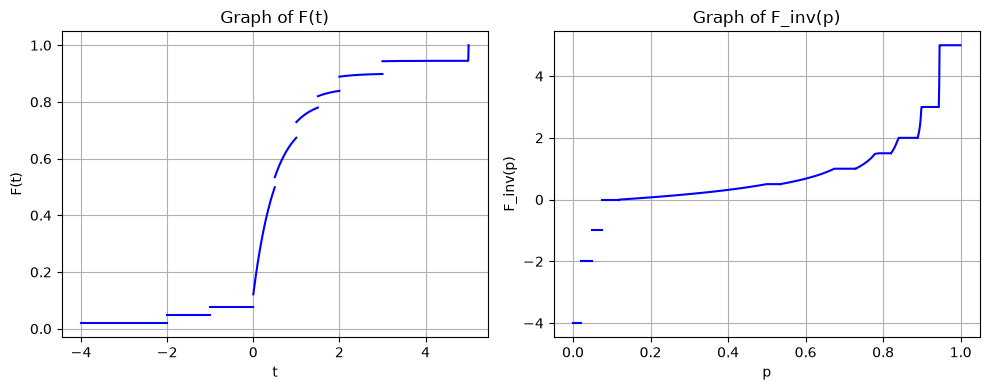

In [79]:
# Реализуем алгорим генерации с помощью F_inverse,
# а также посмотрим на саму F_inverse

def generate_random1():
    u = np.random.uniform(0, 1)
    return F_inverse(u)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

util.plot_function(F, effective_range, critical_points, ax=axes[0], function_name="F", parameter_name="t")
util.plot_function(F_inverse, (0, 1), [F(cp) for cp in critical_points], ax=axes[1], function_name="F_inv", parameter_name="p", theta=1e-2, mu=1e-4)

plt.tight_layout()
plt.show()

# я не уверен почему, но график F_inv(p) не хочет не так охотно разбивается на куски, хотя должен.
# Разрезы должны быть там, где видны острые углы

## 2. Разложение F на дискретный и непрерывный законы

In [80]:
# Высчитываем скачки в критических точках

ROUND_DIGITS = 6
EPSILON = 1e-8

jumps = []

for pp in critical_points:
    jump = round(F(pp + EPSILON) - F(pp - EPSILON), ROUND_DIGITS)
    jumps.append((pp, jump))

print('Jumps:')
print()

for coord, jump in jumps:
    print(f'P(x={coord}) = {jump}')


Jumps:

P(x=-4) = 0.02
P(x=-2) = 0.03
P(x=-1) = 0.025
P(x=0) = 0.045
P(x=0.5) = 0.035
P(x=1) = 0.055
P(x=1.5) = 0.04
P(x=2) = 0.05
P(x=3) = 0.045
P(x=5) = 0.055


In [83]:
# Высчитываем дискретную составляющую функции распределения F
# И выводим в виде кусочно-линейной функции

alpha = sum(j[1] for j in jumps)

cumulative_discrete = 0

print('F_decsr = {')

print(f'  0, x < {jumps[0][0]}')

for i in range(len(jumps) - 1):
    cumulative_discrete = round(cumulative_discrete + jumps[i][1], ROUND_DIGITS)
    print(f'  {round(cumulative_discrete / alpha, ROUND_DIGITS)}, {jumps[i][0]} <= x < {jumps[i + 1][0]}')


cumulative_discrete = round(cumulative_discrete + jumps[-1][1], ROUND_DIGITS)
print(f'  {round(cumulative_discrete / alpha, ROUND_DIGITS)}, x >= {jumps[-1][0]}')

print('}')

def F_discr(x):
    i = 0
    prob = 0
    while i < len(jumps) and x >= jumps[i][0]:
        prob += jumps[i][1] / alpha
        i += 1
    return prob

F_decsr = {
  0, x < -4
  0.05, -4 <= x < -2
  0.125, -2 <= x < -1
  0.1875, -1 <= x < 0
  0.3, 0 <= x < 0.5
  0.3875, 0.5 <= x < 1
  0.525, 1 <= x < 1.5
  0.625, 1.5 <= x < 2
  0.75, 2 <= x < 3
  0.8625, 3 <= x < 5
  1.0, x >= 5
}


In [84]:
# Непрерывная часть
def F_cont(x):
    return (F(x) - alpha * F_discr(x)) / (1 - alpha)

# Разложение распределения F на непрерывную и дискретную составляющие
def F_split(x):
    return alpha * F_discr(x) + (1 - alpha) * F_cont(x)

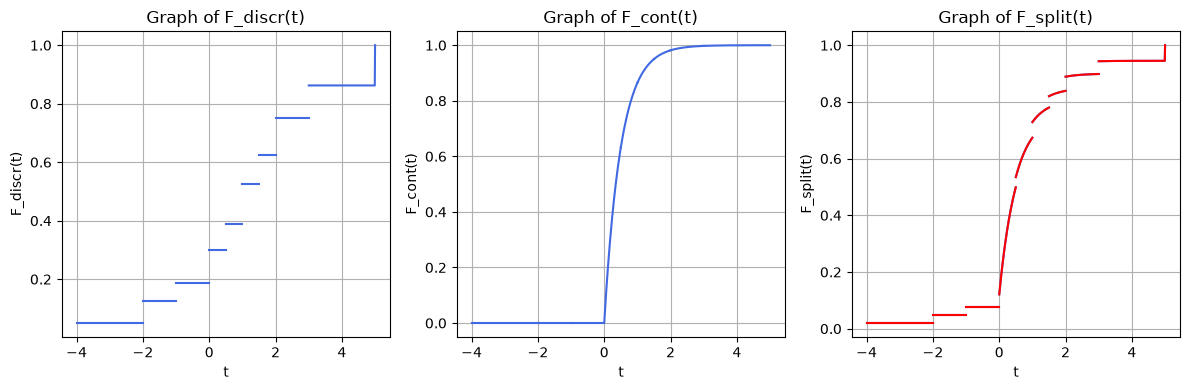

In [87]:
import importlib
import util
importlib.reload(util)

# Изображаем получившееся разложение

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

util.plot_function(F_discr, effective_range, critical_points, ax=axes[0], function_name="F_discr", parameter_name="t")

util.plot_function(F_cont, effective_range, critical_points, ax=axes[1], function_name="F_cont", parameter_name="t")

# На 3 картинке рисуем сразу 2 графика -- оригинальная функция F, а также F_split. В идеале должны совпасть
util.plot_function(F, effective_range, critical_points, ax=axes[2], function_name="F", parameter_name="t")
util.plot_function(F_split, effective_range, critical_points, ax=axes[2], function_name="F_split", parameter_name="t", color='red')

plt.tight_layout()
plt.show()

## 3. Второй алгоритм генерации

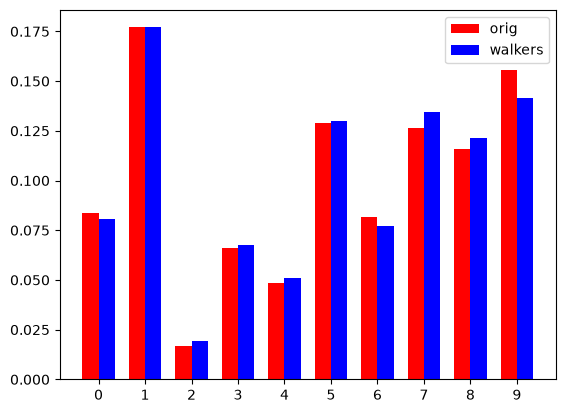

In [88]:
# Тестируем схему Уолкера
util.test_walkers_scheme(n=10, n_iter=5000)

In [89]:
descr_keys = list(map(lambda x: x[0], jumps))
descr_p = list(map(lambda x: x[1], jumps))

F_cont_inverse = util.inverse(F_cont, effective_range)

def generate_random2():
    if np.random.uniform(0, 1) < alpha:
        # discrete
        return descr_keys[util.generate_walkers(p=descr_p)]
    else:
        # continous
        u = np.random.uniform(0, 1)
        return F_cont_inverse(u)

## 4. Проверка корректности обоих алгоритмов 

In [90]:
n_iter = 1000

produced_random1 = [generate_random1() for i in range(n_iter)]
produced_random2 = [generate_random2() for i in range(n_iter)]

F1 = util.build_distr_func(produced_random1)
F2 = util.build_distr_func(produced_random2)

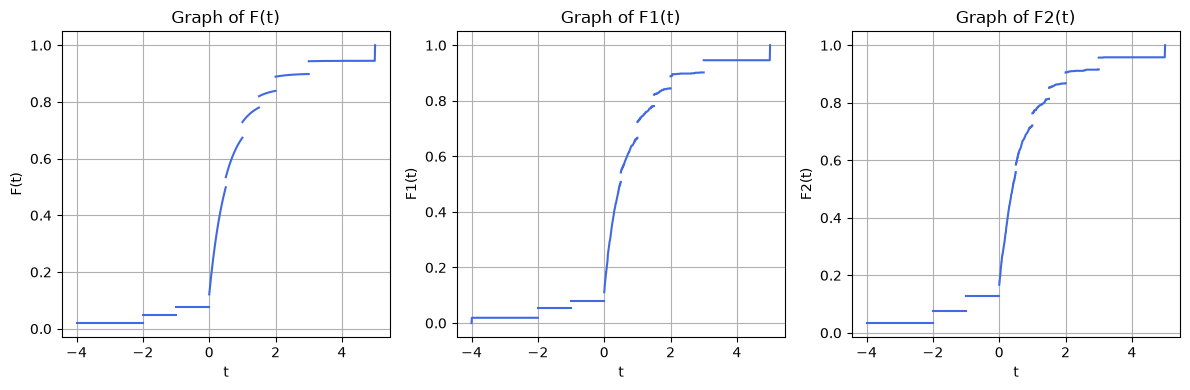

In [92]:
# Изобразим оригинальный F, и полученные с помощью двух алгоритмов F1 и F2

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

util.plot_function(F, effective_range, critical_points, ax=axes[0], function_name="F", parameter_name="t")

util.plot_function(F1, effective_range, critical_points, ax=axes[1], function_name="F1", parameter_name="t")

util.plot_function(F2, effective_range, critical_points, ax=axes[2], function_name="F2", parameter_name="t")

plt.tight_layout()
plt.show()

## 5. Сравнение эффективности реализации теоретически и имперически

Пусть на вызов $F$ тратится $t(F)$ времени

Пусть на вызов $F_{cont}$ тратится $t(F_{cont})$ времени

Пусть мы реализовали функцию поиска значения обратной функции $g^{-1}$ за $t(I(g))$

Пусть случайная величина генерируется за $t(R)$

Используем схему Уолкера за $t(W)$

generate_random1 делает следующее:
1) генерирует одну случайную величину (uniform)
2) ищет значение обратной функции $F^{-1}$ в точке

То есть всего тратит $T1 = t(R) + t(I(F))$

Реализация, которая рандомно генерирует дискретную часть или непрерывную:

1) генерирует одну случайную величину (uniform)
2) Далее с вероятностью $\alpha$ она:
- использует схему Уолкера (генерирует 2 случайные величины + простые операции),
3) С вероятностью $(1 - \alpha)$ она:
- генерирует 1 случайную величину
- ищет значение обратной $F_{cont}$ функции в точке

Матожидание времени ее работы: $E T2 = t(R) + \alpha*(t(W)) + (1 - \alpha)*(t(R) + t(I(F_{cont})))$ 

Положим $t(R) = X$, $t(W) = 2X$, $t(I(F)) = Bt(R) = BX$, $t(I(F_{cont})) = A * t(I(F)) = ABX$

Тогда $T1 = t(R) + t(I(F)) = (B + 1)t(R) = (B + 1)X$

$E T2 = X + \alpha 2X + (1 - \alpha)ABX = X(1 + 2\alpha + (1 - \alpha)AB)$

$\frac{T1}{E T2} = \frac{B + 1}{1 + 2\alpha + (1 - \alpha)AB}$

Если эта величина > 1, то первая функция работает дольше, иначе быстрее.

Заметим, что

$t(I(F)) = O(log_{2}(\frac{b - a}{\epsilon}) * len(bounds))$
$t(I(F_{cont})) = O(log_{2}(\frac{b - a}{\epsilon}) * (len(bounds) + len(jumps)))$

Можно избавиться от $O$ и считать, что перед ними одна и та же константа.
Посчитаем, чему примерно равна $A$

$A = \frac{t(I(F_{cont}))}{t(I(F))} = \frac{len(bounds) + len(jumps)}{len(bounds)}$

B не знаем, придется вычислять имперически

In [50]:
from time import perf_counter
from tqdm import trange

def measure_func(func, n_iter):
    start = perf_counter()
    for i in trange(n_iter):
        func(i)
    return perf_counter() - start

N = 100_000

# подсчитываем заранее, так как это не должно занимать время в моменте
random_values = np.random.uniform(0, 1, size=N)

# считаем чистое время работы рандома (uniform), время F и F_cont 
rand_clean = measure_func(lambda i: np.random.uniform(), N)
f_inv_clean = measure_func(lambda i : F_inverse(random_values[i]), N)

A = (len(bounds) + len(jumps)) / len(bounds)
B = f_inv_clean / rand_clean

z = (B + 1) / (1 + 2 * alpha + (1 - alpha) * A * B)
B, z

100%|██████████| 100000/100000 [00:01<00:00, 75502.39it/s]


(8.76834971896097, 0.8247685896465955)

In [48]:
# z < 1, то есть в целом первая функция должна работать быстрее второй

epoch 0


100%|██████████| 100000/100000 [00:02<00:00, 46428.71it/s]


epoch 1


100%|██████████| 100000/100000 [00:02<00:00, 45113.82it/s]


epoch 2


100%|██████████| 100000/100000 [00:02<00:00, 45896.07it/s]


<Axes: >

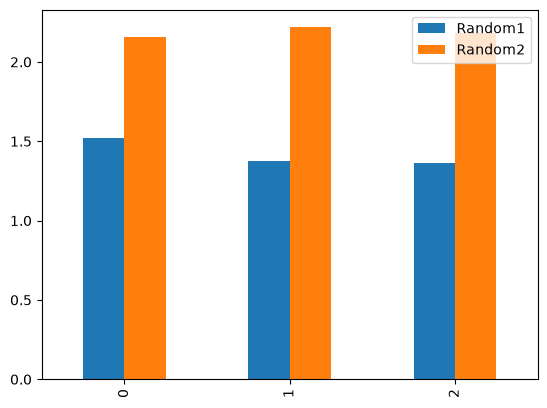

In [49]:
# эмперический замер

import pandas as pd

times1 = []
times2 = []

for epoch in range(3):
    print(f'epoch {epoch}')
    gen1_time = measure_func(lambda i: generate_random1(), N)
    gen2_time = measure_func(lambda i: generate_random2(), N)

    times1.append(gen1_time)
    times2.append(gen2_time)

stats = pd.DataFrame({
    'Random1': times1,
    'Random2': times2
})

stats.plot(kind='bar')

In [43]:
# Первая функция действительно работает быстрее